In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# Connect and Access Git Repository

import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
Cloning into '/content/bachelor-thesis'...
remote: Enumerating objects: 362, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (86/86), done.
remote: Total 362 (delta 51), reused 29 (delta 12), pack-reused 264 (from 1)
Receiving objects: 100% (362/362), 22.30 MiB | 13.18 MiB/s, done.
Resolving deltas: 100% (168/168), done.
/content/bachelor-thesis
Repo exists: True


In [ ]:
!git pull

Already up to date.


In [3]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve
)


# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))

from utils.dataset import PTBXLTranADDataset
from explainability.attention import TranADExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.tranad import TranADMainModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [11]:
DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRANAD_MODEL_PATH = MODEL_DIR / "tranad_20epochs_larger_capacity.pt"
TRANAD_RESULTS_PATH = RESULTS_DIR / "tranad_20epochs_larger_capacity_results.npz"

print("MODEL_DIR:", MODEL_DIR)
print("TRANAD_MODEL_PATH:", TRANAD_MODEL_PATH)
print("TRANAD_RESULTS_PATH:", TRANAD_RESULTS_PATH)

MODEL_DIR: /content/drive/MyDrive/ECG data/results/models
TRANAD_MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/tranad_20epochs_larger_capacity.pt
TRANAD_RESULTS_PATH: /content/drive/MyDrive/ECG data/results/tranad_20epochs_larger_capacity_results.npz


In [12]:
# Load my preprocessed data

X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))

X_val = np.load(os.path.join(PROCESSED_DIR, "X_val.npy"))
y_val = np.load(os.path.join(PROCESSED_DIR, "y_val.npy"))

X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))


print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(17418, 1000, 12)
(2183, 1000, 12)
(2198, 1000, 12)


In [13]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [14]:
# Datasets

train_dataset = PTBXLTranADDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLTranADDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLTranADDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [15]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

In [16]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([16, 1000, 12])
#         Batch y: torch.Size([16])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [17]:
# Create Model

TranAD = TranADMainModel(
    NumFeatures=12,
    ModelDimension=64,
    NumHeads=4,
    NumEncoderLayers=2,
    NumDecoderLayers=2,
    ForwardDimension=128,
    DropoutRate=0.1,
    LearningRate=1e-4,
    FocusGrowthRate=1.05,
    InitialFocusScore=1.0,
    MaxFocusScore=5.0,
    AnomalyPercentile=95.0,
)

TranADModel: 268,376 Parameter | d_model=64, H=4, Enc=2, Dec×2=2


In [18]:
# Test

batch_x = batch_x.to(TranAD.Device)

x1, x2 = TranAD.Network(batch_x)

print(x1.shape)
print(x2.shape)

torch.Size([4, 1000, 12])
torch.Size([4, 1000, 12])


In [ ]:
# Load saved model instead of training

TranAD.Load(str(TRANAD_MODEL_PATH))

Model loaded  /content/drive/MyDrive/ECG data/results/models/tranad_15epochs.pt


In [19]:
# reset the anomay threshold because we have a new calculating technique
TranAD.AnomalyThreshold = None

In [ ]:
# Those are saved results from the previous training

LoadedResults = np.load(TRANAD_RESULTS_PATH)

AnomalyScores = LoadedResults["AnomalyScores"]
BinaryPredictions = LoadedResults["BinaryPredictions"]
y_test = LoadedResults["y_test"]

print("Loaded scores:", AnomalyScores.shape)
print("Loaded predictions:", BinaryPredictions.shape)
print("Loaded threshold:", LoadedResults["Threshold"])

Loaded scores: (2198,)
Loaded predictions: (2198,)
Loaded threshold: 0.3394192159175873


In [20]:
# Training

print("\n── TranAD Training starts ─────────────────────────────")

TranAD.TrainModel(
    TrainingLoader = train_loader,
    NumEpochs      = 20,
    PrintInterval  = 1,
)


── TranAD Training starts ─────────────────────────────
Epoche    1/20 | Loss=1.00332 | φ=1.05 | LR=1.00e-04
Epoche    2/20 | Loss=0.55830 | φ=1.10 | LR=1.00e-04
Epoche    3/20 | Loss=0.43922 | φ=1.16 | LR=1.00e-04
Epoche    4/20 | Loss=0.37827 | φ=1.22 | LR=1.00e-04
Epoche    5/20 | Loss=0.33903 | φ=1.28 | LR=1.00e-04
Epoche    6/20 | Loss=0.31361 | φ=1.34 | LR=1.00e-04
Epoche    7/20 | Loss=0.29589 | φ=1.41 | LR=1.00e-04
Epoche    8/20 | Loss=0.28413 | φ=1.48 | LR=1.00e-04
Epoche    9/20 | Loss=0.27973 | φ=1.55 | LR=1.00e-04
Epoche   10/20 | Loss=0.27147 | φ=1.63 | LR=1.00e-04
Epoche   11/20 | Loss=0.26824 | φ=1.71 | LR=1.00e-04
Epoche   12/20 | Loss=0.26534 | φ=1.80 | LR=1.00e-04
Epoche   13/20 | Loss=0.26628 | φ=1.89 | LR=1.00e-04
Epoche   14/20 | Loss=0.26694 | φ=1.98 | LR=1.00e-04
Epoche   15/20 | Loss=0.26712 | φ=2.08 | LR=1.00e-04
Epoche   16/20 | Loss=0.27072 | φ=2.18 | LR=1.00e-04
Epoche   17/20 | Loss=0.27120 | φ=2.29 | LR=1.00e-04
Epoche   18/20 | Loss=0.27435 | φ=2.41 | L

In [21]:
# Calculating scores from validation set

ValidationScores = TranAD.CalculateScores(DataLoaderObject=val_loader)

ValidationLabels = np.asarray(y_val).astype(int).reshape(-1)

print("Validation scores shape:", ValidationScores.shape,)
print("Validation labels shape:", ValidationLabels.shape,)
print("Normal validation records:", (ValidationLabels == 0).sum(),)
print("Anomalous validation records:", (ValidationLabels == 1).sum(),)
print("Mean normal score:", ValidationScores[ValidationLabels == 0].mean(),)
print("Mean anomalous score:", ValidationScores[ValidationLabels == 1].mean(),)

Validation scores shape: (2183,)
Validation labels shape: (2183,)
Normal validation records: 955
Anomalous validation records: 1228
Mean normal score: 0.015654061
Mean anomalous score: 0.11856051


In [22]:
# New Threshold calculation method based on Validation scores

def ChooseThresholdForRecall(
    Labels: np.ndarray,
    Scores: np.ndarray,
    TargetRecall: float,
) -> dict:
    """
    Selects a validation threshold that achieves at least
    TargetRecall.

    Among the valid thresholds, it selects the threshold
    with the highest precision.
    """

    PrecisionValues, RecallValues, ThresholdValues = (
        precision_recall_curve(
            Labels,
            Scores,
        )
    )

    # The final precision and recall values have
    # no corresponding threshold
    PrecisionValues = PrecisionValues[:-1]
    RecallValues = RecallValues[:-1]

    ValidIndices = np.where(
        RecallValues >= TargetRecall
    )[0]

    if len(ValidIndices) == 0:
        raise ValueError(
            f"No threshold achieved recall "
            f">= {TargetRecall:.2f}."
        )

    ValidPrecision = PrecisionValues[ValidIndices]

    HighestPrecision = ValidPrecision.max()

    BestCandidates = ValidIndices[
        np.isclose(
            ValidPrecision,
            HighestPrecision,
        )
    ]

    # In a precision tie, select the highest threshold.
    BestIndex = BestCandidates[
        np.argmax(
            ThresholdValues[
                BestCandidates
            ]
        )
    ]

    return {
        "Threshold": float(ThresholdValues[BestIndex]),
        "Precision": float(PrecisionValues[BestIndex]),
        "Recall": float(RecallValues[BestIndex]),
        }

In [23]:
# choose Threshold

ThresholdResult = ChooseThresholdForRecall(
    Labels=ValidationLabels,
    Scores=ValidationScores,
    TargetRecall=0.80,
)

ChosenThreshold = ThresholdResult["Threshold"]

print("Chosen threshold:", ChosenThreshold)
print("Validation precision:", ThresholdResult["Precision"])
print("Validation recall:", ThresholdResult["Recall"])

Chosen threshold: 0.010166172869503498
Validation precision: 0.6132252027448534
Validation recall: 0.8004885993485342


In [24]:
# Anomaly detection

print("\n── TranAD Anomaly Detection ─────────────────────────────")


AnomalyScores, BinaryPredictions = (
    TranAD.DetectAnomalies(
        TestLoader=test_loader,
        Threshold=ChosenThreshold,
    )
)


print("Test scores shape:", AnomalyScores.shape)
print("Test predictions shape:", BinaryPredictions.shape)
print("Detected anomalous records:", BinaryPredictions.sum())
print("Validation-derived threshold:", TranAD.AnomalyThreshold)


── TranAD Anomaly Detection ─────────────────────────────
Test scores shape: (2198,)
Test predictions shape: (2198,)
Detected anomalous records: 1626
Validation-derived threshold: 0.010166172869503498


In [25]:
# Evaluation

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

Metrics = TranAD.Evaluate(
    TrueLabels=TestLabels,
    Scores=AnomalyScores,
    PredictedLabels=BinaryPredictions,
)

ROC_AUC = roc_auc_score(
    TestLabels,
    AnomalyScores,
)

PR_AUC = average_precision_score(
    TestLabels,
    AnomalyScores,
)

ConfMatrix = confusion_matrix(
    TestLabels,
    BinaryPredictions,
)

print("\nConfusion matrix:\n", ConfMatrix )
print("ROC-AUC:", round(ROC_AUC, 4))
print("PR-AUC:", round(PR_AUC, 4))


TranAD Evaluation Results ──────────────────
  Accuracy            : 0.6065
  Precision           : 0.6138
  Recall              : 0.8081
  F1Score             : 0.6977
  FalseNegativeRate   : 0.1919
  Threshold           : 0.010166
  TruePositive        : 998
  TrueNegative        : 335
  FalsePositive       : 628
  FalseNegative       : 237

Confusion matrix:
 [[335 628]
 [237 998]]
ROC-AUC: 0.6695
PR-AUC: 0.7348


In [26]:
# @title
# Save the Model

print("\n── Saving TranAD model ────────────────────────────────")

TranAD.Save(str(TRANAD_MODEL_PATH))


── Saving TranAD model ────────────────────────────────
Model saved  /content/drive/MyDrive/ECG data/results/models/tranad_20epochs_larger_capacity.pt


In [27]:
# @title
# Save the results

print("\n── Saving TranAD results ──────────────────────────────")

np.savez(
    TRANAD_RESULTS_PATH,
    AnomalyScores=AnomalyScores,
    BinaryPredictions=BinaryPredictions,
    y_test=y_test,
    ConfusionMatrix=ConfMatrix,
    ROC_AUC=ROC_AUC,
    PR_AUC=PR_AUC,
    Threshold=TranAD.AnomalyThreshold,
)

print("Saved results to:", TRANAD_RESULTS_PATH)


── Saving TranAD results ──────────────────────────────
Saved results to: /content/drive/MyDrive/ECG data/results/tranad_20epochs_larger_capacity_results.npz



── TranAD Attention-based Explainability ─────────────────────
Selected normal index: 2044
Normal score: 0.0037761503
Selected anomalous index: 69
Anomalous score: 2.6535122


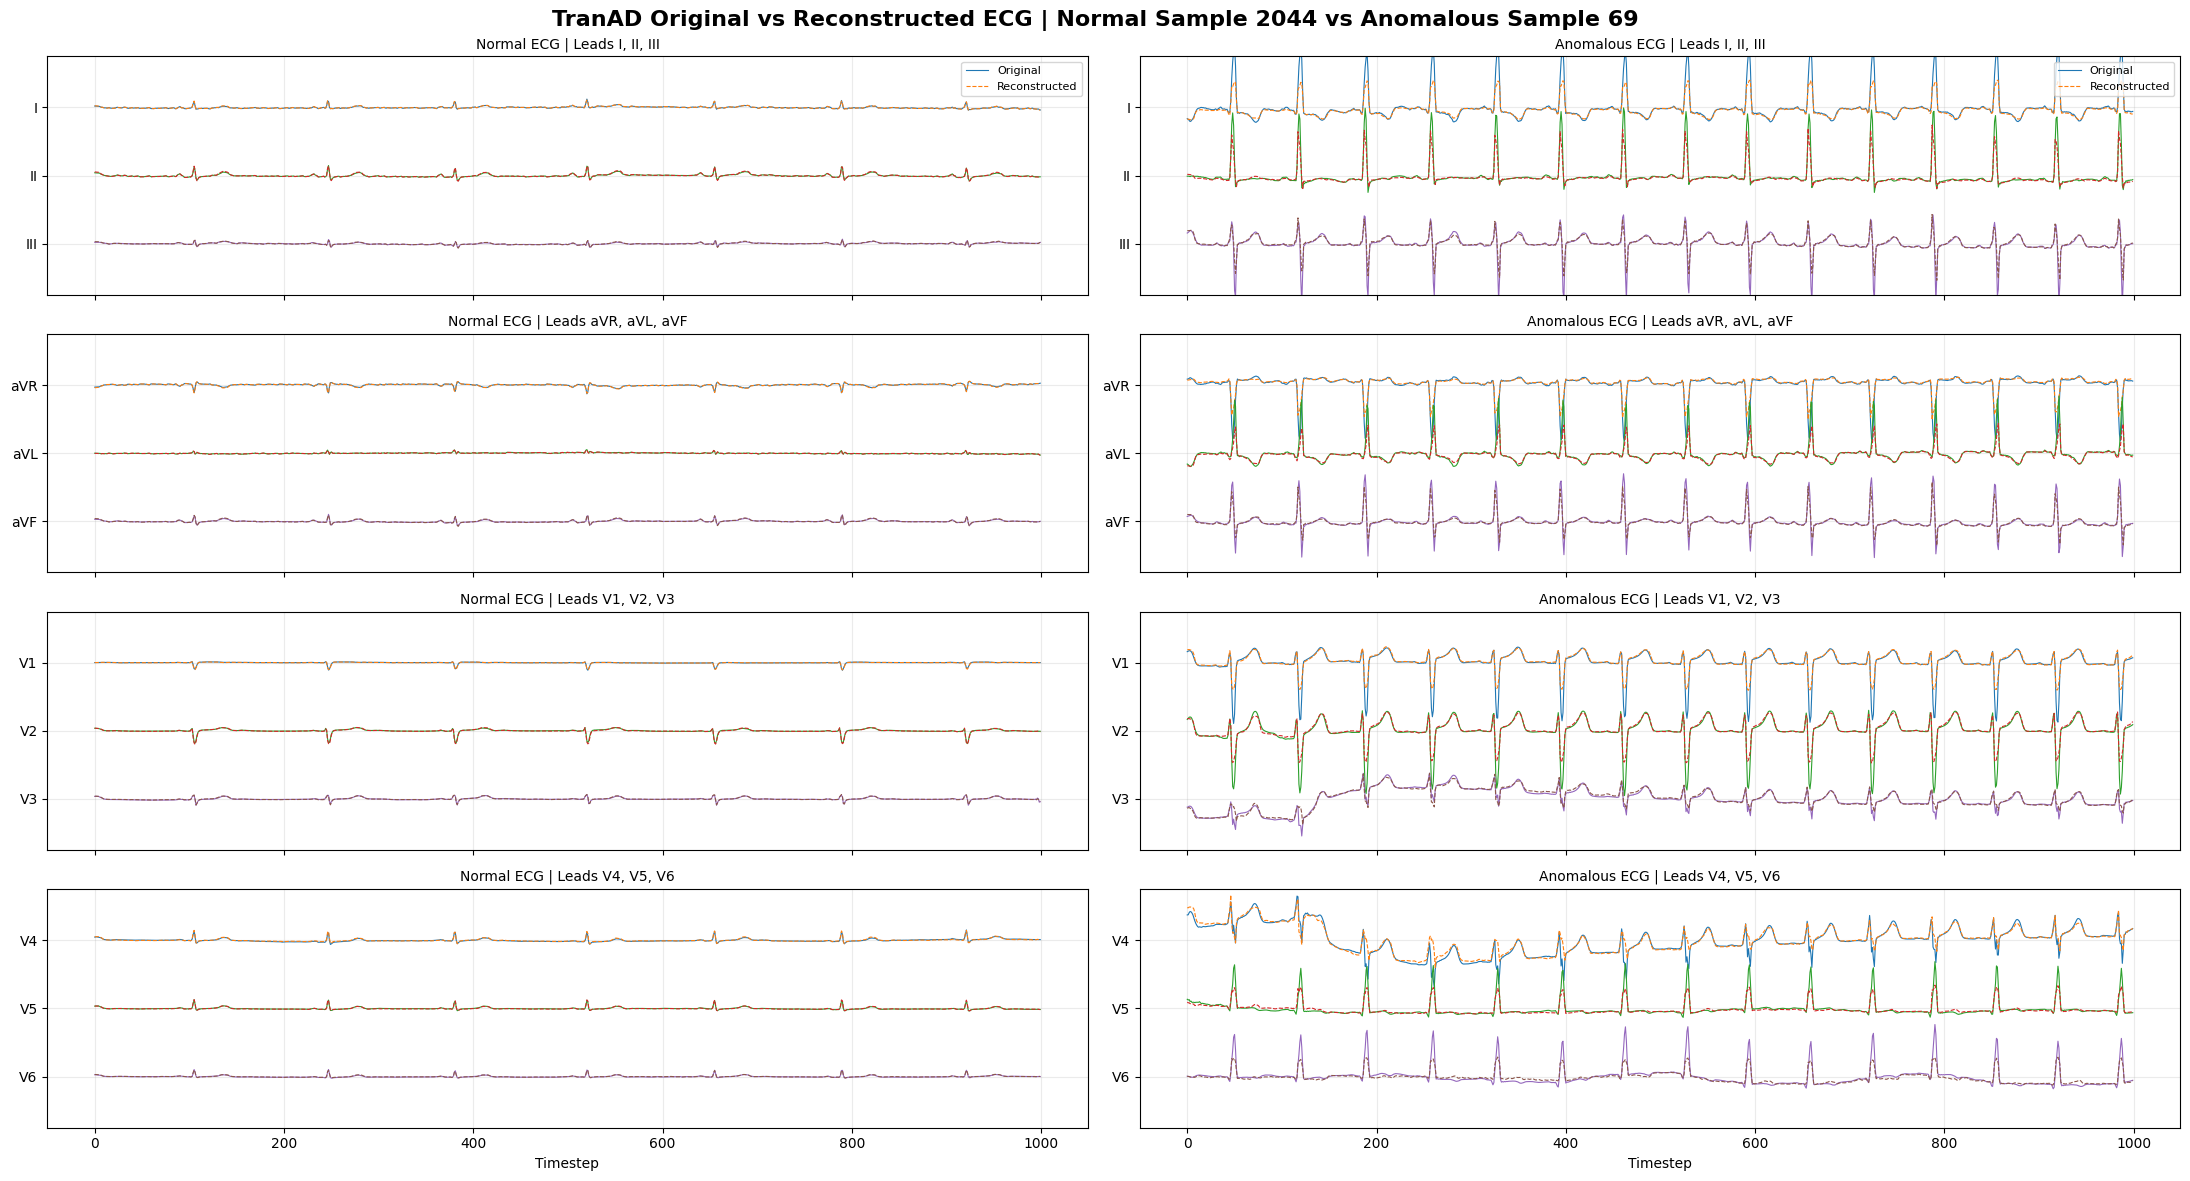

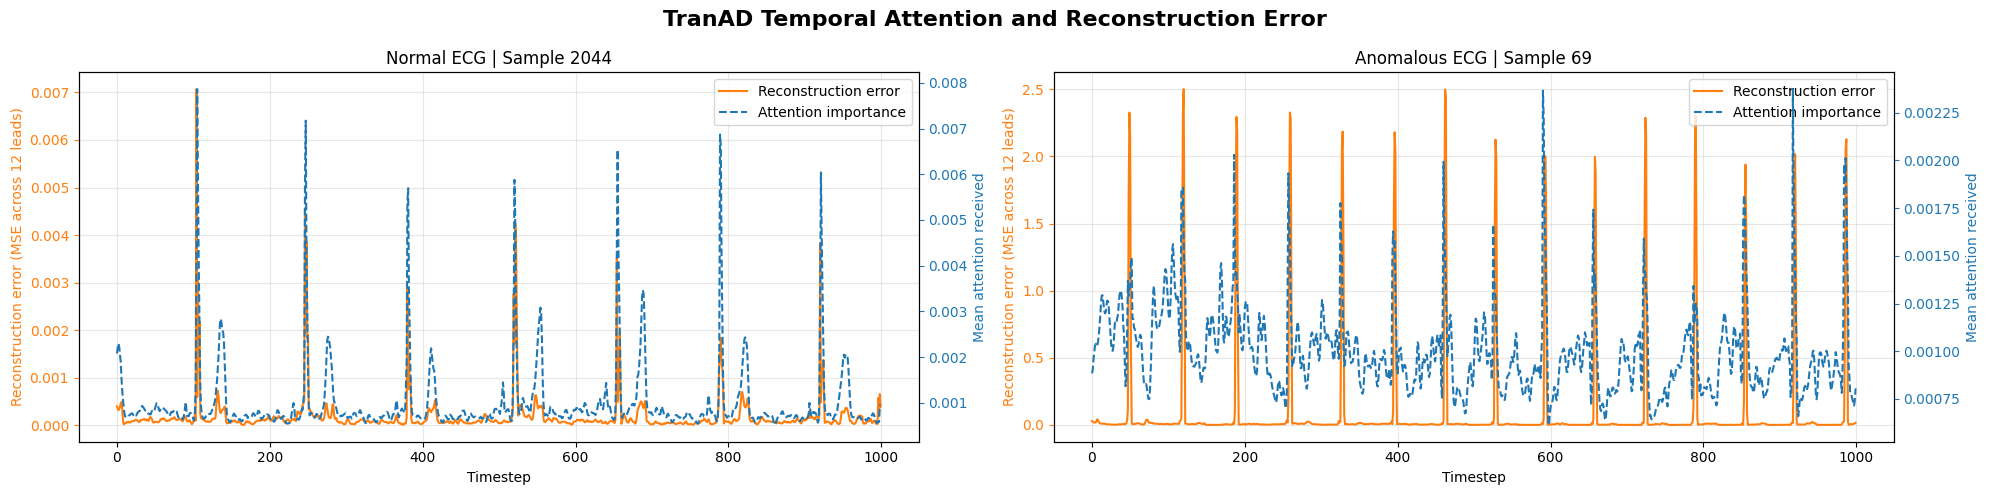

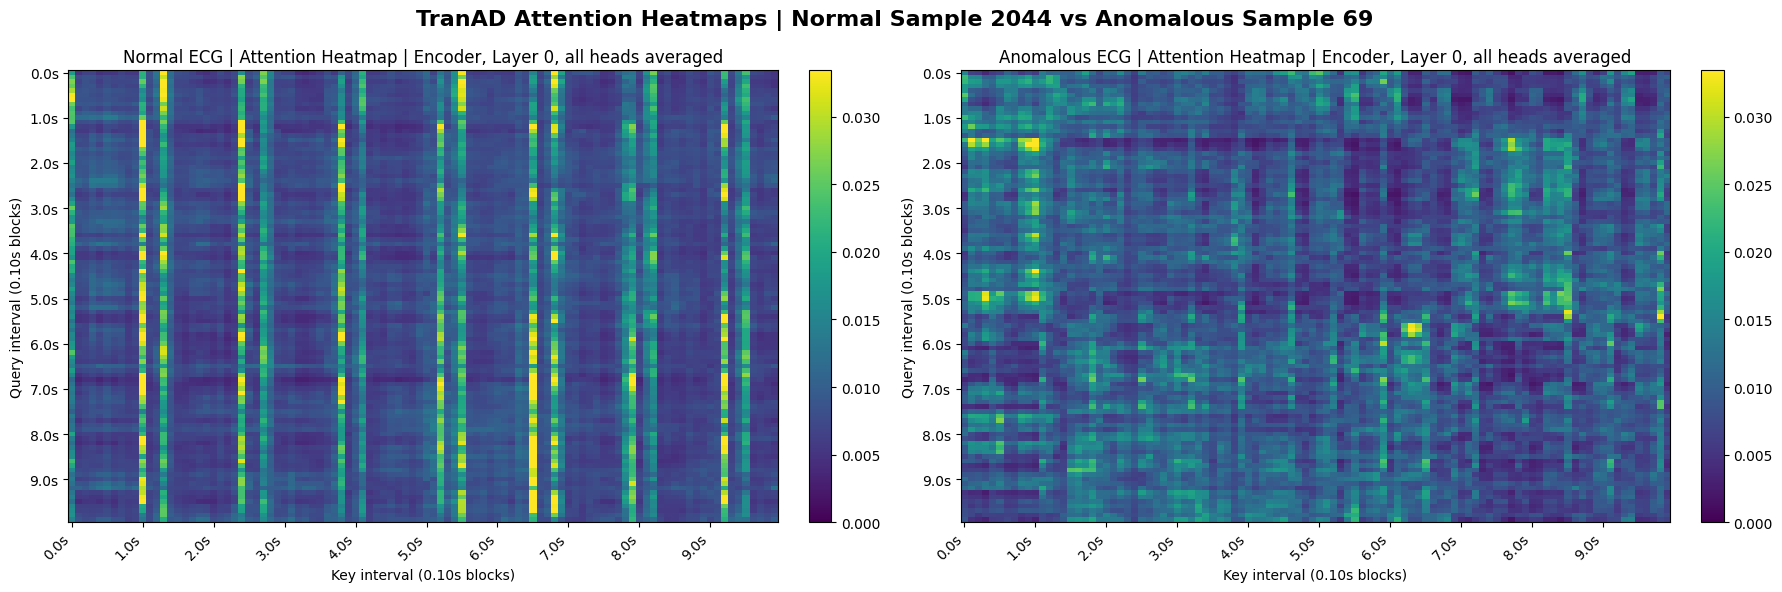

In [28]:
# TranAD Attention-based Explainability

import numpy as np

print("\n── TranAD Attention-based Explainability ─────────────────────")

Explainer = TranADExplainability(TranAD)

# Select meaningful samples, not arbitrary first samples
correct_normal = np.where(
    (y_test == 0) & (BinaryPredictions == 0)
)[0]

correct_anomaly = np.where(
    (y_test == 1) & (BinaryPredictions == 1)
)[0]

NormalIndex = correct_normal[
    np.argmin(AnomalyScores[correct_normal])
]

AnomalousIndex = correct_anomaly[
    np.argmax(AnomalyScores[correct_anomaly])
]

print("Selected normal index:", NormalIndex)
print("Normal score:", AnomalyScores[NormalIndex])

print("Selected anomalous index:", AnomalousIndex)
print("Anomalous score:", AnomalyScores[AnomalousIndex])

NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(TranAD.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(TranAD.Device)

Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Encoder",
    LayerIndex=0,
    HeadIndex=None,      # all heads averaged
    Percentile=99.0,
    UseIntervalHeatmap=True,
    BlockSize=10,
    Aggregation="mean_attention_mass",
    SamplingRate=100,
)

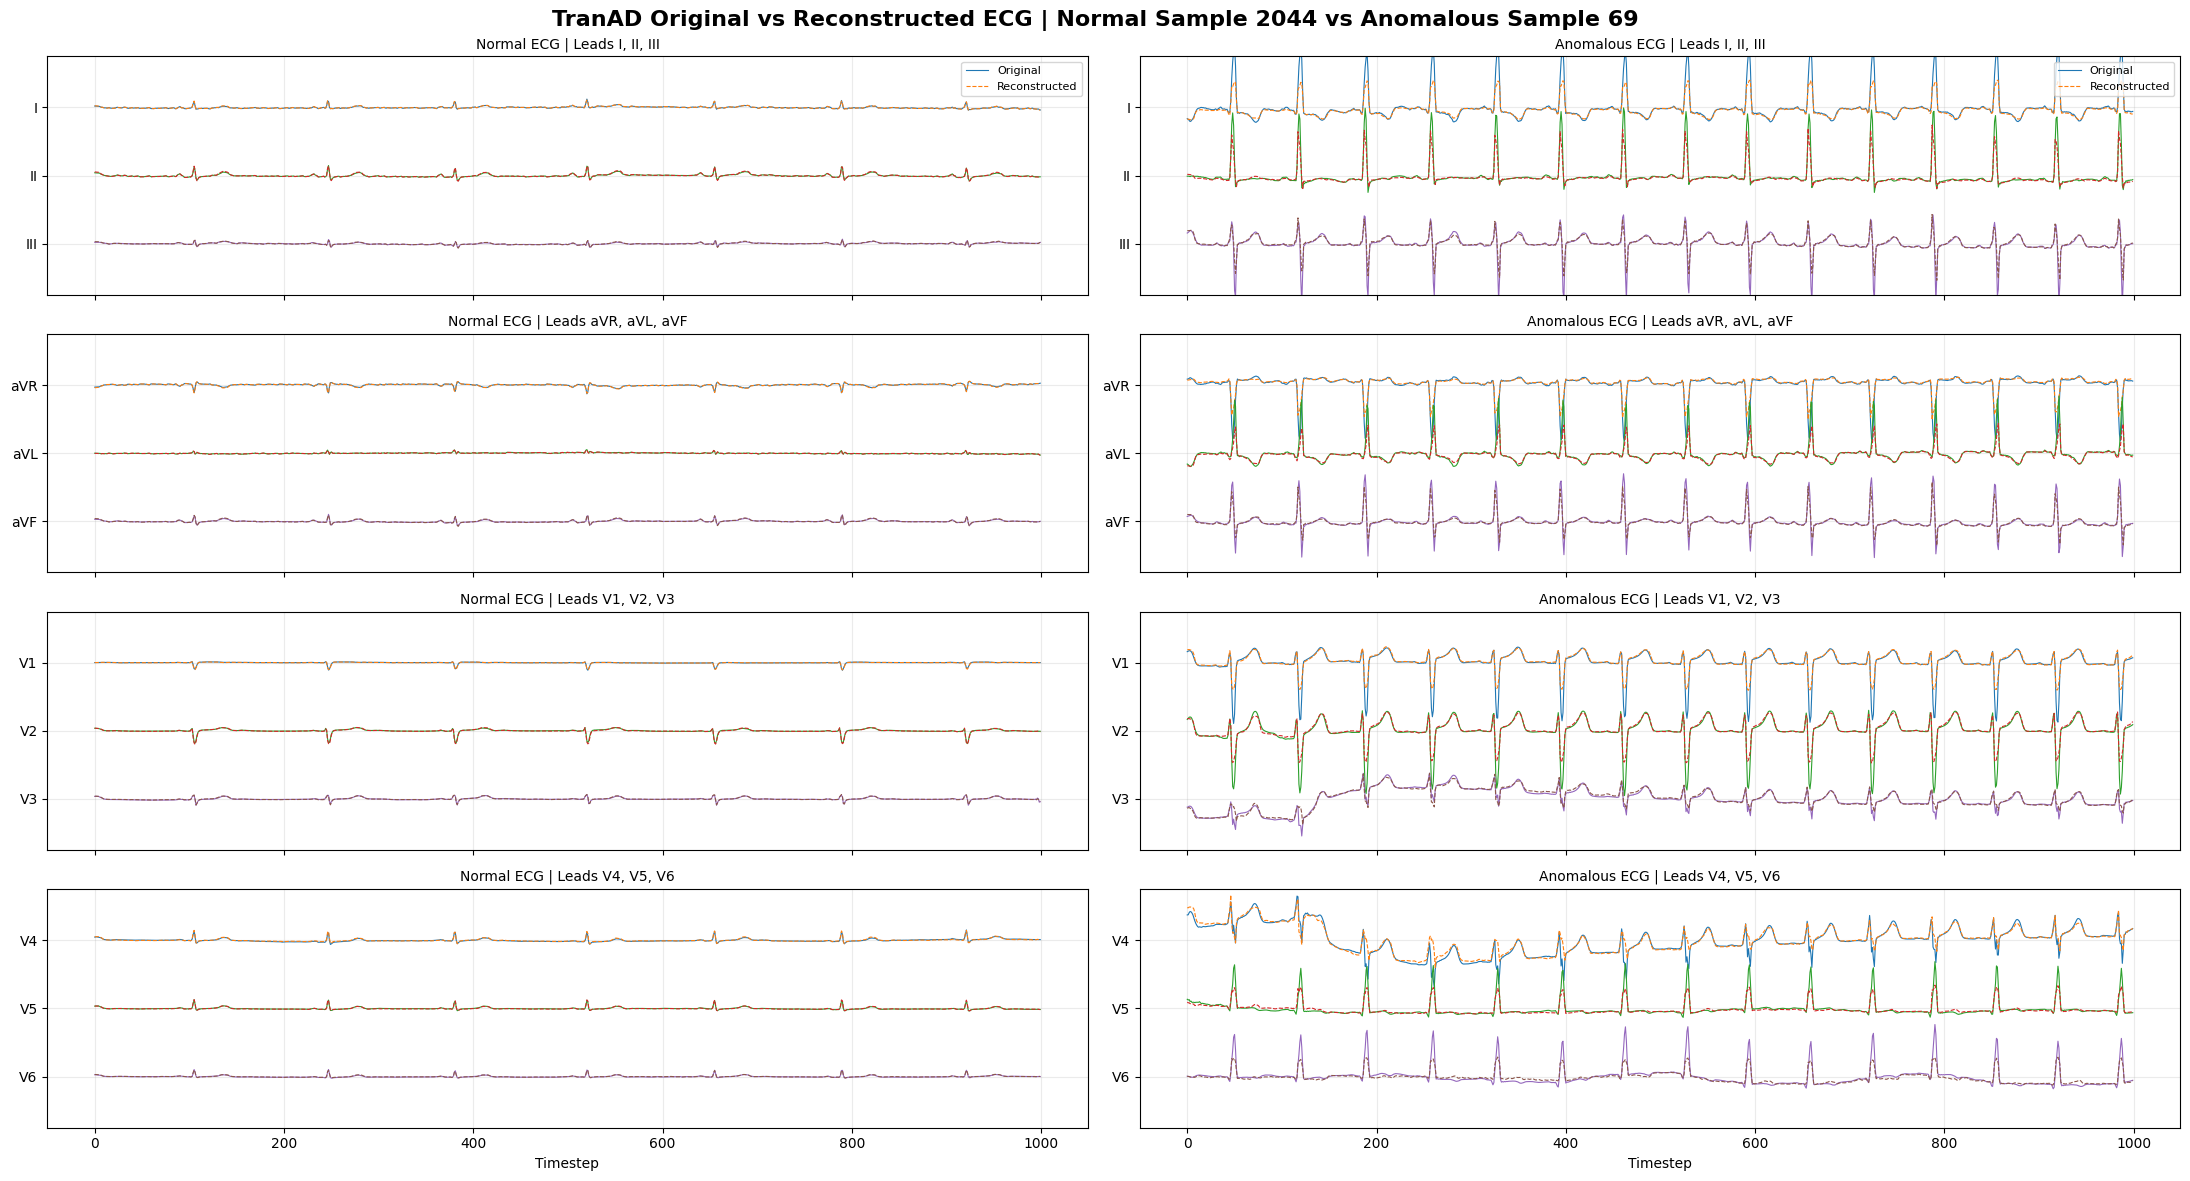

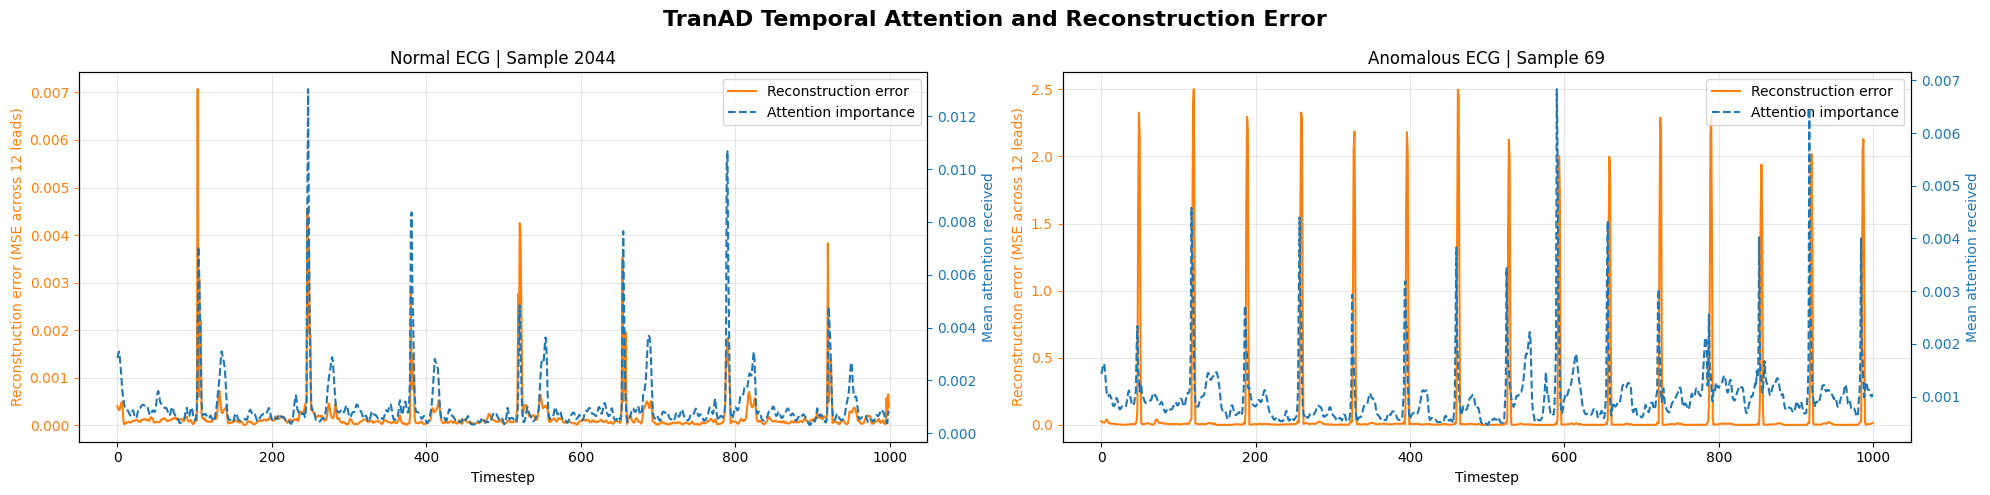

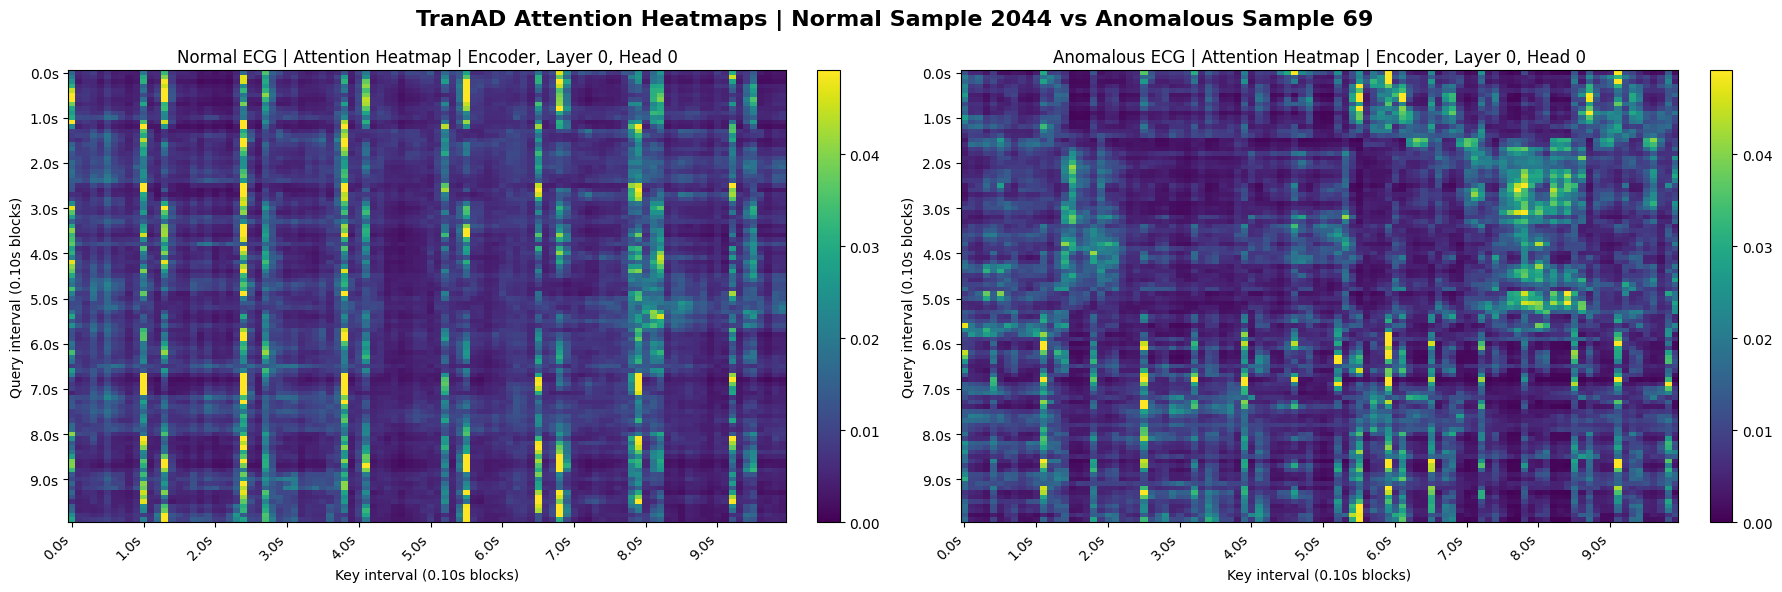

In [29]:
# Only Head 0
Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Encoder",
    LayerIndex=0,
    HeadIndex=0,
    Percentile=99.0,
)

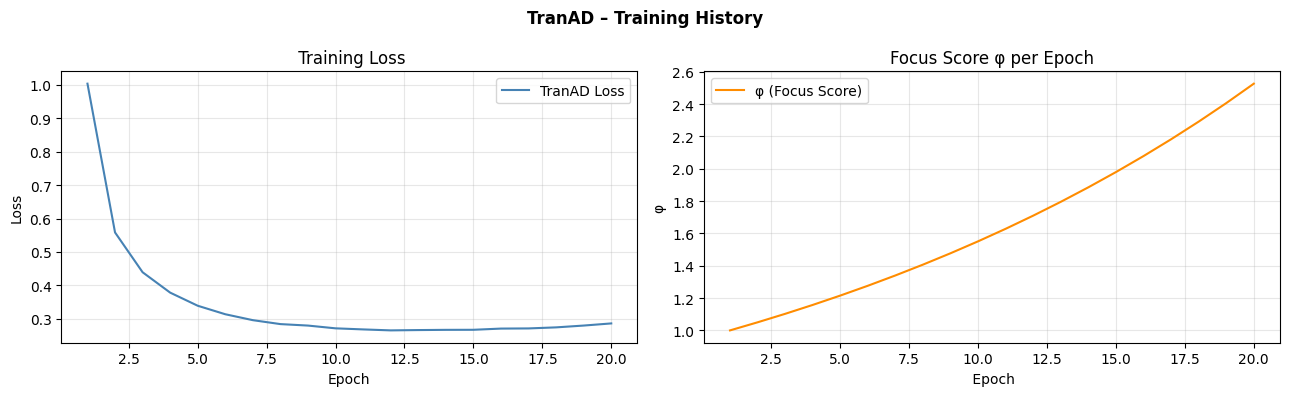

In [30]:
# Show training loss

Explainer.ShowTrainingHistory()